
# Notebook 6: Outlier Treatment

## Objective
Understand how to detect, analyze, and appropriately treat outliers
without losing valuable information.

## Learning Outcomes
- Understand outliers and distinguish them from errors.
- Detect outliers using IQR, Z-score, and percentile methods.
- Apply Winsorization, capping, flooring, and transformations.
- Compare removing outliers with retaining them.
- Document the reason for each outlier treatment decision.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
data = {
    "Employee_ID": range(1, 16),
    "Salary": [
        25000, 28000, 30000, 32000, 35000,
        36000, 38000, 40000, 42000, 45000,
        48000, 50000, 55000, 60000, 250000
    ]
}

df_outliers = pd.DataFrame(data)

print("Sample dataset:")
display(df_outliers)

print("\nSalary statistics:")
display(df_outliers["Salary"].describe())

Sample dataset:


,Employee_ID,Salary
0,1,25000
1,2,28000
2,3,30000
3,4,32000
4,5,35000
5,6,36000
6,7,38000
7,8,40000
8,9,42000
9,10,45000



Salary statistics:


count        15.000000
mean      54266.666667
std       55060.313250
min       25000.000000
25%       33500.000000
50%       40000.000000
75%       49000.000000
max      250000.000000
Name: Salary, dtype: float64


## 1. What Is an Outlier?

An outlier is an observation that differs substantially from
the general pattern of the other observations.

Outliers can occur because of:
- Data-entry or measurement errors.
- Unusual but valid real-world events.
- Natural variation in the population.
- Data integration or recording problems.

An outlier is not necessarily an error. Its meaning must be
investigated using domain knowledge and the context of the data.



## 2. Outlier Versus Error

**Outlier:** An observation unusually far from the other values.

**Error:** A value that is incorrect because of recording,
measurement, processing, or other data-quality problems.

Example:
- A very high salary may be valid for a senior executive.
- A salary entered as 2,500,000 instead of 250,000 may be an error.

A statistical method can flag unusual observations, but it
cannot determine by itself whether the values are incorrect.


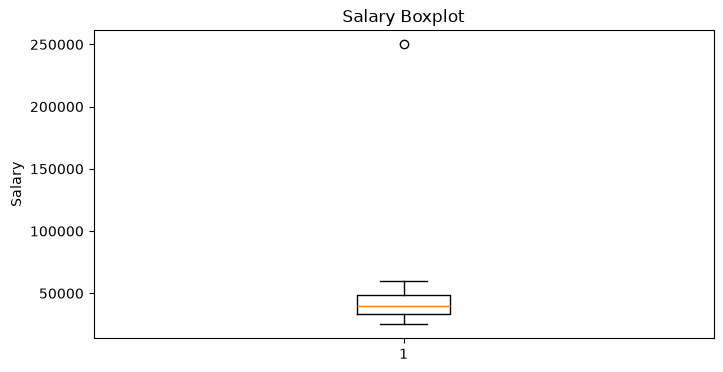

In [3]:
plt.figure(figsize=(8, 4))
plt.boxplot(df_outliers["Salary"].dropna())
plt.title("Salary Boxplot")
plt.ylabel("Salary")
plt.show()

In [4]:
Q1 = df_outliers["Salary"].quantile(0.25)
Q3 = df_outliers["Salary"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

iqr_outliers = df_outliers[
    (df_outliers["Salary"] < lower_bound)
    | (df_outliers["Salary"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

print("\nDetected outliers:")
display(iqr_outliers)

Q1: 33500.0
Q3: 49000.0
IQR: 15500.0
Lower bound: 10250.0
Upper bound: 72250.0

Detected outliers:


,Employee_ID,Salary
14,15,250000


In [5]:
salary_mean = df_outliers["Salary"].mean()
salary_std = df_outliers["Salary"].std()

df_outliers["Salary_ZScore"] = (
    (df_outliers["Salary"] - salary_mean) / salary_std
)

zscore_outliers = df_outliers[
    df_outliers["Salary_ZScore"].abs() > 3
]

print("Mean salary:", salary_mean)
print("Standard deviation:", salary_std)

print("\nOutliers with absolute Z-score greater than 3:")
display(zscore_outliers[["Employee_ID", "Salary", "Salary_ZScore"]])

Mean salary: 54266.666666666664
Standard deviation: 55060.31325045377

Outliers with absolute Z-score greater than 3:


,Employee_ID,Salary,Salary_ZScore
14,15,250000,3.55489


In [6]:
lower_percentile = df_outliers["Salary"].quantile(0.01)
upper_percentile = df_outliers["Salary"].quantile(0.99)

percentile_outliers = df_outliers[
    (df_outliers["Salary"] < lower_percentile)
    | (df_outliers["Salary"] > upper_percentile)
]

print("1st percentile:", lower_percentile)
print("99th percentile:", upper_percentile)

print("\nValues outside percentile bounds:")
display(percentile_outliers[["Employee_ID", "Salary"]])

1st percentile: 25420.0
99th percentile: 223399.99999999988

Values outside percentile bounds:


,Employee_ID,Salary
0,1,25000
14,15,250000


In [7]:
from scipy.stats.mstats import winsorize

df_outliers["Salary_Winsorized"] = winsorize(
    df_outliers["Salary"],
    limits=[0.05, 0.05]
)

display(
    df_outliers[
        ["Salary", "Salary_Winsorized"]
    ]
)

,Salary,Salary_Winsorized
0,25000,25000
1,28000,28000
2,30000,30000
3,32000,32000
4,35000,35000
5,36000,36000
6,38000,38000
7,40000,40000
8,42000,42000
9,45000,45000


In [8]:
df_outliers["Salary_Capped"] = df_outliers["Salary"].clip(
    upper=upper_bound
)

df_outliers["Salary_Floored"] = df_outliers["Salary"].clip(
    lower=lower_bound
)

display(
    df_outliers[
        ["Salary", "Salary_Capped", "Salary_Floored"]
    ]
)

,Salary,Salary_Capped,Salary_Floored
0,25000,25000,25000
1,28000,28000,28000
2,30000,30000,30000
3,32000,32000,32000
4,35000,35000,35000
5,36000,36000,36000
6,38000,38000,38000
7,40000,40000,40000
8,42000,42000,42000
9,45000,45000,45000


,Salary,Salary_Log
0,25000,10.126671
1,28000,10.239996
2,30000,10.308986
3,32000,10.373522
4,35000,10.463132
5,36000,10.491302
6,38000,10.545368
7,40000,10.596660
8,42000,10.645449
9,45000,10.714440


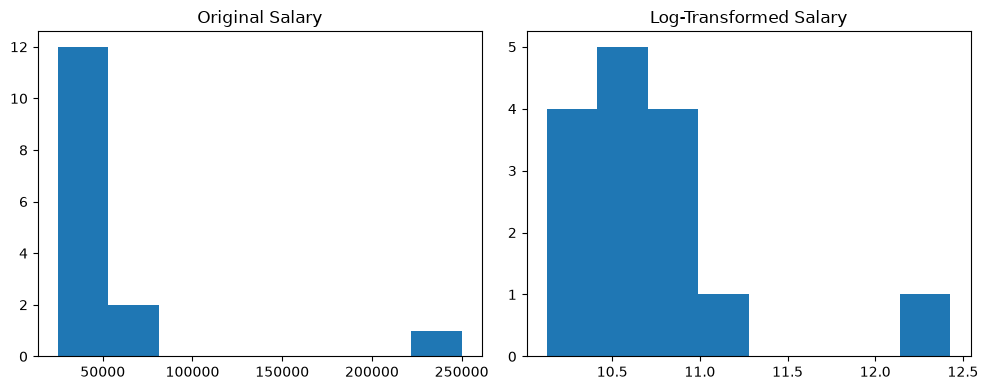

In [9]:
df_outliers["Salary_Log"] = np.log1p(df_outliers["Salary"])

display(
    df_outliers[
        ["Salary", "Salary_Log"]
    ]
)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(df_outliers["Salary"], bins=8)
axes[0].set_title("Original Salary")

axes[1].hist(df_outliers["Salary_Log"], bins=8)
axes[1].set_title("Log-Transformed Salary")

plt.tight_layout()
plt.show()

In [10]:
df_removed = df_outliers[
    df_outliers["Salary"].between(lower_bound, upper_bound)
].copy()

print("Original rows:", len(df_outliers))
print("Rows after IQR filtering:", len(df_removed))
print("Rows removed:", len(df_outliers) - len(df_removed))

display(df_removed[["Employee_ID", "Salary"]])

Original rows: 15
Rows after IQR filtering: 14
Rows removed: 1


,Employee_ID,Salary
0,1,25000
1,2,28000
2,3,30000
3,4,32000
4,5,35000
5,6,36000
6,7,38000
7,8,40000
8,9,42000
9,10,45000



## Retaining Outliers

Outliers should be retained when they represent valid observations
that are important to the analysis.

Examples include:
- High salaries of senior executives.
- Unusually large but valid property transactions.
- Rare but genuine equipment failures.
- Exceptional demand during special events.

Before retaining an outlier, check its source, units, business
context, and consistency with other records.

Retaining valid outliers helps preserve real-world variation.
However, their influence on statistical analysis and model
performance should still be evaluated.



## Retaining Outliers

Outliers should be retained when they represent valid observations
that are important to the analysis.

Examples include:
- High salaries of senior executives.
- Unusually large but valid property transactions.
- Rare but genuine equipment failures.
- Exceptional demand during special events.

Before retaining an outlier, check its source, units, business
context, and consistency with other records.

Retaining valid outliers helps preserve real-world variation.
However, their influence on statistical analysis and model
performance should still be evaluated.



## Conclusion

In this notebook, I learned how to detect outliers using the
IQR, Z-score, and percentile methods.

I practiced Winsorization, capping, flooring, logarithmic
transformation, and removing outliers.

I also learned to distinguish statistical outliers from data
errors and to retain valid extreme observations when appropriate.

Outlier treatment should be based on evidence, business context,
and the intended machine learning task rather than automatic
deletion.
